# Reto avanzado 3 · Estabilidad de clusters: Jackknife Clustering

**Malackathon 2026 · Mercedes-Benz · "Clustering the Star"**

Objetivo: comprobar que la segmentación de clientes (K-Means con k = 6) es **robusta** antes de basar decisiones de marketing en ella. Un modelo
puede tener buenos valores de silueta y, aun así, ser inestable: si pequeños cambios en los datos cambian los segmentos, las campañas se
dirigirían a grupos que no existen de forma consistente.

La pregunta es: **si eliminamos un subconjunto aleatorio de clientes y volvemos a entrenar el modelo, ¿se mantienen los mismos segmentos?**
Este notebook cubre:

1. Datos y modelo de referencia
2. Implementación del Jackknife Clustering
3. Estabilidad de las asignaciones
4. Análisis por clúster
5. ¿Qué clientes saltan entre clústeres y por qué?
6. Conclusiones y recomendación final

## 1. Datos y modelo de referencia

Usamos exactamente los mismos datos y el mismo modelo que en el cuaderno 03:

- **Matriz del modelo** (`X_model_fe2.pkl`): 173.456 clientes y 18 columnas codificadas y escaladas.
- **Segmentación de referencia** (`clientes_clusters.csv`): el clúster que el K-Means final (k = 6) asignó a cada cliente.
- **Nombres de los segmentos** (`clientes_segmentos_k6.csv`, del cuaderno 04), para interpretar los resultados en lenguaje de negocio.

Todos los cruces se hacen por `client_id` y se comprueba con `assert` que no se pierde ni se duplica ningún cliente.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import plot_style as ps
import mb_features as mf

ps.apply()
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
DATA_DIR = ROOT / "data"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

import time
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_samples

df_prepared = pd.read_pickle(DATA_DIR / "X_model_fe2.pkl")
assert df_prepared.index.is_unique, "hay client_id duplicados en la matriz del modelo"
X = df_prepared.values
N_CLIENTES = len(X)
K = 6

referencia = pd.read_csv(DATA_DIR / "clientes_clusters.csv", usecols=["client_id", "cluster"], dtype={"client_id": str})
assert referencia["client_id"].is_unique, "clientes_clusters.csv tiene client_id duplicados"
cruce = pd.DataFrame({"client_id": df_prepared.index}).merge(referencia, on="client_id", how="left", validate="one_to_one")
assert len(cruce) == N_CLIENTES and cruce["cluster"].notna().all(), "faltan clientes en la segmentación de referencia"
REF = cruce["cluster"].to_numpy().astype(int)

fichero_nombres = DATA_DIR / "clientes_segmentos_k6.csv"
if fichero_nombres.exists():
    nombres = pd.read_csv(fichero_nombres, usecols=["cluster", "segmento"]).drop_duplicates()
    assert nombres["cluster"].is_unique, "un clúster tiene más de un nombre"
    NOMBRE = {int(c): f"{c} · {s}" for c, s in zip(nombres["cluster"], nombres["segmento"])}
else:
    NOMBRE = {c: f"Clúster {c}" for c in range(K)}

print(f"{N_CLIENTES:,} clientes · {X.shape[1]} columnas · k = {K}")
pd.Series(REF).map(NOMBRE).value_counts().reindex([NOMBRE[c] for c in range(K)]).rename("clientes").to_frame()

173,456 clientes · 18 columnas · k = 6


,clientes
0 · El Sénior Recién Llegado,29388
1 · El Ejecutivo Premium AMG,26245
2 · El Conductor en Leasing,31980
3 · El Joven Aspiracional,30809
4 · El Veterano a Renovar,21510
5 · El Fiel del Taller Oficial,33524


## 2. Implementación del Jackknife Clustering

**Procedimiento:**

1. Generamos **N = 20 submuestras**. Cada una **excluye al azar el 15 % de los clientes** (dentro del rango del 10-20 % propuesto) y conserva
   el 85 % restante, unos 147.000 clientes.
2. En cada submuestra entrenamos **K-Means con el mismo k óptimo (k = 6)** y los mismos parámetros que el modelo final (`n_init=10`,
   `random_state=42`). Fijamos la semilla del algoritmo a propósito: así, lo único que cambia entre ejecuciones son **los clientes**, que es
   justo lo que queremos medir.
3. Guardamos el clúster que recibe cada cliente presente en la submuestra.

**Alineación de etiquetas.** K-Means numera los clústeres de forma arbitraria: el segmento que en el modelo final es el "2" puede llamarse "4"
en otra ejecución aunque contenga a los mismos clientes. Antes de comparar hay que **emparejar** cada clúster de la ejecución con el de la
referencia. Para ello usamos el **método húngaro** (`linear_sum_assignment`), que elige el emparejamiento uno a uno que maximiza el número de
clientes coincidentes. Sin este paso, dos segmentaciones idénticas podrían parecer totalmente distintas.

In [2]:
N_SUBMUESTRAS = 20
FRACCION_EXCLUIDA = 0.15
rng = np.random.default_rng(42)

def alinear(etiquetas_ref, etiquetas):
    """Renombra los clústeres de `etiquetas` para que coincidan al máximo con `etiquetas_ref` (método húngaro)."""
    tabla = pd.crosstab(etiquetas_ref, etiquetas).reindex(index=range(K), columns=range(K), fill_value=0).to_numpy()
    filas, columnas = linear_sum_assignment(-tabla)            # maximizar coincidencias = minimizar su negativo
    mapa = np.empty(K, dtype=int)
    mapa[columnas] = filas
    return mapa[etiquetas]

# ASIGNACIONES[r, i] = clúster (ya alineado) del cliente i en la ejecución r; -1 si el cliente quedó excluido
ASIGNACIONES = np.full((N_SUBMUESTRAS, N_CLIENTES), -1, dtype=int)
ejecuciones = []
t0 = time.time()
for r in range(N_SUBMUESTRAS):
    incluidos = np.sort(rng.choice(N_CLIENTES, int(N_CLIENTES * (1 - FRACCION_EXCLUIDA)), replace=False))
    modelo = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X[incluidos])
    alineadas = alinear(REF[incluidos], modelo.labels_)
    ASIGNACIONES[r, incluidos] = alineadas
    ejecuciones.append({
        "ejecución": r + 1,
        "clientes usados": len(incluidos),
        "coincidencia con la referencia (%)": (alineadas == REF[incluidos]).mean() * 100,
        "ARI con la referencia": adjusted_rand_score(REF[incluidos], modelo.labels_),
    })
ejecuciones = pd.DataFrame(ejecuciones).set_index("ejecución")
ejecuciones.to_csv(ROOT / "reports" / "A3_ejecuciones.csv")
print(f"20 modelos entrenados en {time.time() - t0:.0f} s")

apariciones = (ASIGNACIONES >= 0).sum(axis=0)
assert apariciones.min() >= 2, "hay clientes que no aparecen en al menos dos submuestras"
print(f"Cada cliente aparece en {apariciones.min()}-{apariciones.max()} submuestras (media {apariciones.mean():.1f}): "
      "todos están presentes en varias ejecuciones y se pueden comparar.")

20 modelos entrenados en 23 s
Cada cliente aparece en 8-20 submuestras (media 17.0): todos están presentes en varias ejecuciones y se pueden comparar.


## 3. Estabilidad de las asignaciones

Medimos la estabilidad con dos métricas:

- **Porcentaje de coincidencia de asignación:** de los clientes presentes en dos segmentaciones, qué porcentaje está en el mismo clúster
  (tras la alineación). Es la métrica que pide el reto y la más fácil de comunicar.
- **ARI (Adjusted Rand Index):** compara dos segmentaciones sin depender de la numeración de los clústeres. Vale 1 si son idénticas y 0 si
  coinciden lo mismo que por azar. Sirve de control de que la alineación no está inflando la coincidencia.

### 3.1 Cada submuestra frente al modelo de referencia

,coincidencia con la referencia (%),ARI con la referencia
mean,99.4756,0.9878
min,99.2838,0.9827
max,99.8406,0.9961


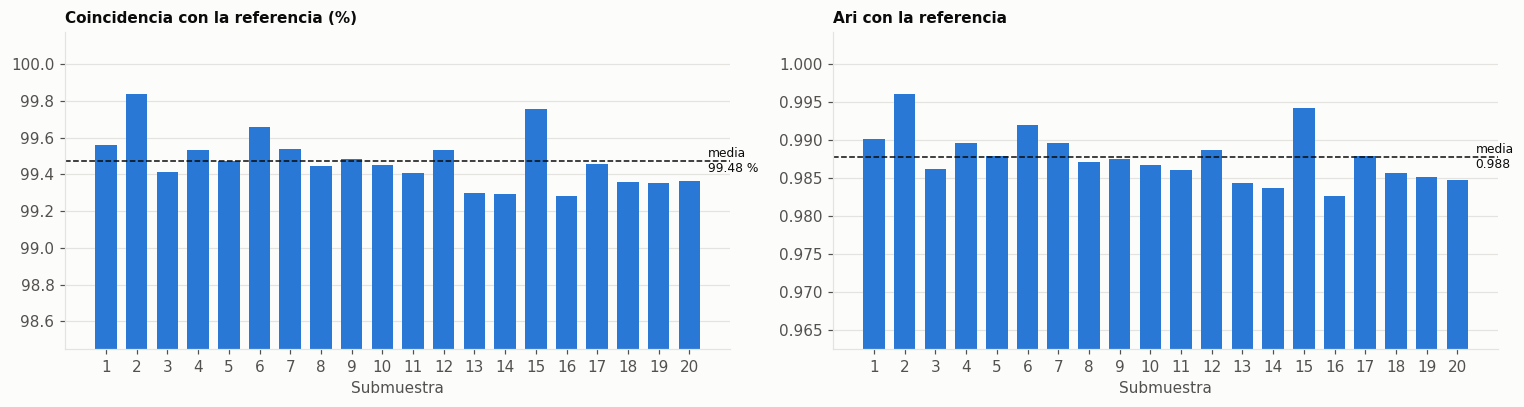

In [3]:
display(ejecuciones.describe().loc[["mean", "min", "max"]].drop(columns="clientes usados").round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
for ax, col, fmt in [(axes[0], "coincidencia con la referencia (%)", "{:.2f} %"), (axes[1], "ARI con la referencia", "{:.3f}")]:
    v = ejecuciones[col]
    ax.bar(v.index, v.values, color=ps.SERIES[0], width=0.7)
    ax.set_ylim(v.min() - (v.max() - v.min()) * 1.5, v.max() + (v.max() - v.min()) * 0.6)
    ax.axhline(v.mean(), color=ps.INK, ls="--", lw=1)
    ax.text(N_SUBMUESTRAS + 0.6, v.mean(), "media\n" + fmt.format(v.mean()), va="center", fontsize=8, color=ps.INK)
    ax.set_xticks(v.index); ax.set_xlabel("Submuestra"); ax.set_title(col.capitalize(), fontsize=10)
    ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(FIG_DIR / "A3_coincidencia_por_ejecucion.png"); plt.show()

En **todas** las submuestras más del 99 % de los clientes recibe el mismo segmento que en el modelo final, y el ARI se mantiene en torno a 0,99.
Excluir a un 15 % de los clientes apenas mueve la segmentación. (Ojo con la escala vertical: está ampliada para que se vean las pequeñas
diferencias entre ejecuciones.)

### 3.2 Comparación entre submuestras

La comparación con la referencia podría estar favorecida porque el modelo final se entrenó con todos los clientes. Por eso comparamos también
**cada par de submuestras entre sí** (190 pares), usando solo los clientes que están presentes en ambas.

Coincidencia entre pares de submuestras: media 99.40 % · mínima 98.77 %
ARI entre pares de submuestras:          media 0.9862 · mínimo 0.9716


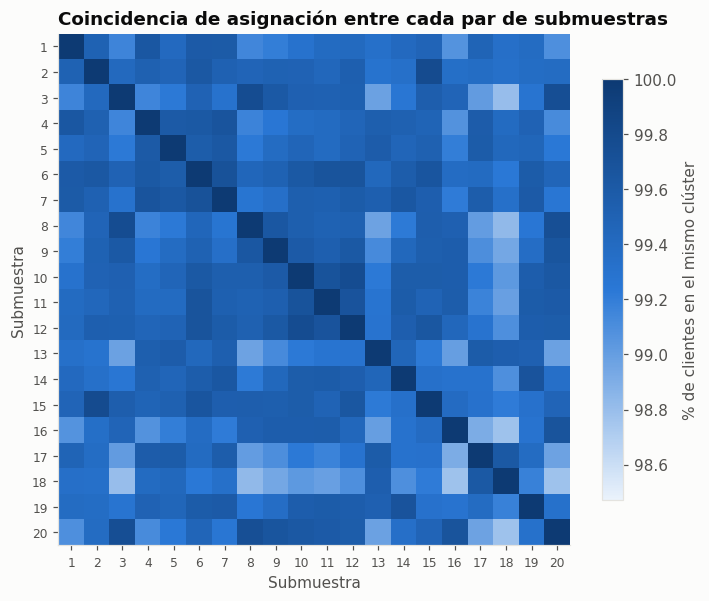

In [4]:
coincidencia_pares = np.full((N_SUBMUESTRAS, N_SUBMUESTRAS), 100.0)
ari_pares = []
for i in range(N_SUBMUESTRAS):
    for j in range(i + 1, N_SUBMUESTRAS):
        ambos = (ASIGNACIONES[i] >= 0) & (ASIGNACIONES[j] >= 0)
        c = (ASIGNACIONES[i][ambos] == ASIGNACIONES[j][ambos]).mean() * 100
        coincidencia_pares[i, j] = coincidencia_pares[j, i] = c
        ari_pares.append(adjusted_rand_score(ASIGNACIONES[i][ambos], ASIGNACIONES[j][ambos]))
triangulo = coincidencia_pares[np.triu_indices(N_SUBMUESTRAS, k=1)]
print(f"Coincidencia entre pares de submuestras: media {triangulo.mean():.2f} % · mínima {triangulo.min():.2f} %")
print(f"ARI entre pares de submuestras:          media {np.mean(ari_pares):.4f} · mínimo {np.min(ari_pares):.4f}")
pd.Series({"coincidencia_media_%": triangulo.mean(), "coincidencia_min_%": triangulo.min(),
           "ari_medio": np.mean(ari_pares), "ari_min": np.min(ari_pares), "n_pares": len(triangulo)},
          name="valor").to_csv(ROOT / "reports" / "A3_pares.csv")

fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(coincidencia_pares, cmap=ps.SEQ_BLUE, vmin=triangulo.min() - 0.3, vmax=100)
ax.set_xticks(range(N_SUBMUESTRAS), range(1, N_SUBMUESTRAS + 1), fontsize=8)
ax.set_yticks(range(N_SUBMUESTRAS), range(1, N_SUBMUESTRAS + 1), fontsize=8); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label="% de clientes en el mismo clúster")
ax.set_xlabel("Submuestra"); ax.set_ylabel("Submuestra")
ax.set_title("Coincidencia de asignación entre cada par de submuestras")
fig.savefig(FIG_DIR / "A3_coincidencia_pares.png"); plt.show()

Entre submuestras la coincidencia es igual de alta que frente a la referencia: el mapa es prácticamente uniforme, sin ninguna ejecución que se
desvíe del resto. **Los seis segmentos se reproducen de forma consistente** sea cual sea el 15 % de clientes que se excluya.

### 3.3 Estabilidad de cada cliente

Para cada cliente calculamos su **estabilidad individual**: el porcentaje de las submuestras en las que aparece en las que recibe el mismo
clúster que en el modelo de referencia. Un 100 % significa que nunca cambia de segmento.

,clientes,% de clientes
100 % (nunca cambia),170367,98.22
80-99 %,1391,0.80
50-79 %,1107,0.64
menos del 50 %,591,0.34


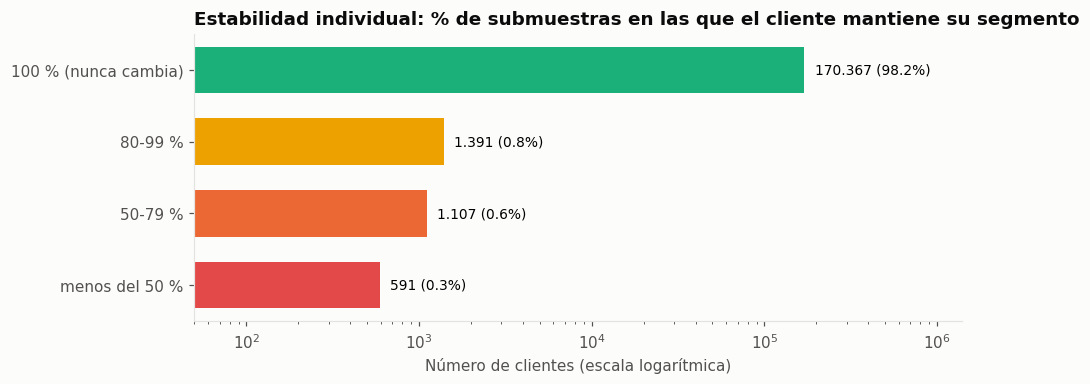

In [5]:
presente = ASIGNACIONES >= 0
estabilidad = ((ASIGNACIONES == REF) & presente).sum(axis=0) / presente.sum(axis=0) * 100

TRAMOS = ["100 % (nunca cambia)", "80-99 %", "50-79 %", "menos del 50 %"]
tramo = pd.cut(estabilidad, bins=[-0.1, 49.99, 79.99, 99.99, 100], labels=TRAMOS[::-1])
reparto = tramo.value_counts().reindex(TRAMOS)
tabla_tramos = pd.DataFrame({"clientes": reparto, "% de clientes": (reparto / N_CLIENTES * 100).round(2)})
tabla_tramos.to_csv(ROOT / "reports" / "A3_tramos_estabilidad.csv")
display(tabla_tramos)

fig, ax = plt.subplots(figsize=(9, 3.4))
colores_t = [ps.SERIES[2], ps.SERIES[3], ps.SERIES[1], ps.SERIES[7]]
barras = ax.barh(TRAMOS[::-1], reparto[::-1].values, color=colores_t[::-1], height=0.65)
for b, v in zip(barras, reparto[::-1].values):
    ax.text(b.get_width() * 1.15, b.get_y() + b.get_height() / 2, f"{v:,.0f} ({v / N_CLIENTES:.1%})".replace(",", "."),
            va="center", fontsize=9)
ax.set_xscale("log"); ax.set_xlim(50, N_CLIENTES * 8)
ax.set_xlabel("Número de clientes (escala logarítmica)"); ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
ax.set_title("Estabilidad individual: % de submuestras en las que el cliente mantiene su segmento")
fig.savefig(FIG_DIR / "A3_estabilidad_clientes.png"); plt.show()

La inmensa mayoría de los clientes **nunca cambia de segmento** en ninguna de las 20 submuestras. Solo una pequeña minoría cambia alguna vez
y muy pocos lo hacen con frecuencia (la escala logarítmica permite ver esos grupos pequeños junto al mayoritario). A estos clientes que cambian
de clúster entre ejecuciones los llamamos **clientes que saltan**.

## 4. Análisis por clúster

### 4.1 ¿Hay algún segmento especialmente inestable?

Para cada segmento del modelo de referencia resumimos la estabilidad de sus clientes: la coincidencia media, el porcentaje de clientes que nunca
cambian y el porcentaje de clientes inestables (estabilidad inferior al 80 %).

,clientes,coincidencia media (%),% nunca cambian,% inestables (<80 %),nº inestables
2 · El Conductor en Leasing,31980,99.85,99.39,0.26,84
1 · El Ejecutivo Premium AMG,26245,99.50,98.56,0.97,254
0 · El Sénior Recién Llegado,29388,99.44,98.10,0.98,287
5 · El Fiel del Taller Oficial,33524,99.40,98.31,1.04,350
3 · El Joven Aspiracional,30809,99.38,97.67,1.23,380
4 · El Veterano a Renovar,21510,99.18,96.86,1.59,343


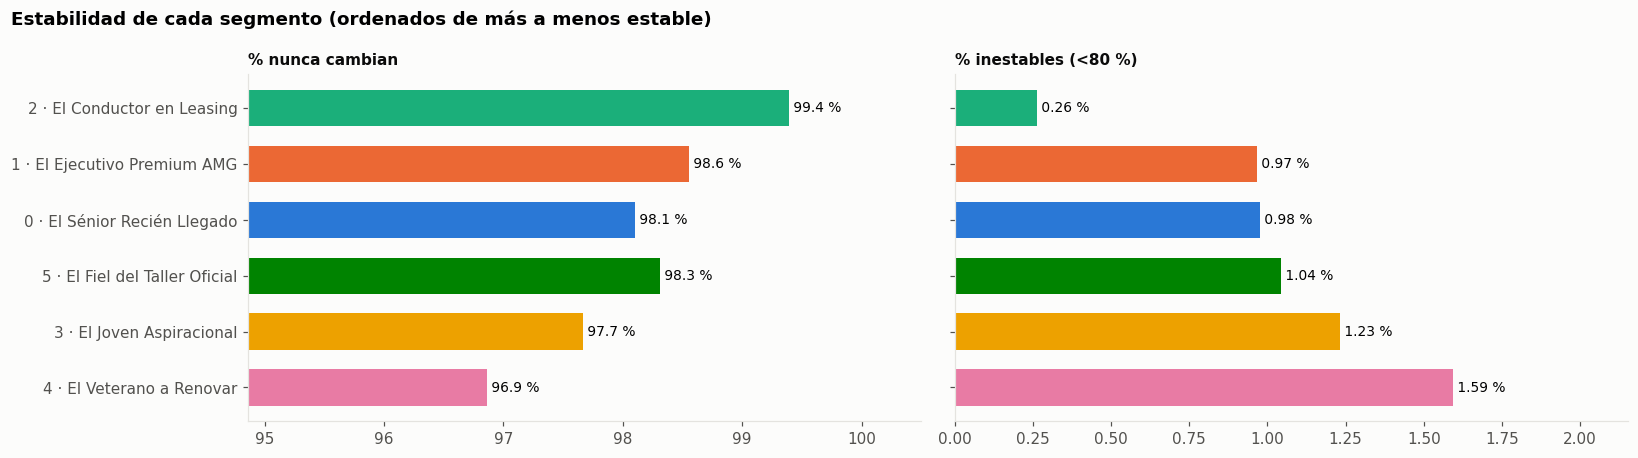

In [6]:
por_cluster = (pd.DataFrame({"cluster": REF, "estabilidad": estabilidad})
               .groupby("cluster")["estabilidad"]
               .agg(**{"clientes": "size",
                       "coincidencia media (%)": "mean",
                       "% nunca cambian": lambda v: (v == 100).mean() * 100,
                       "% inestables (<80 %)": lambda v: (v < 80).mean() * 100,
                       "nº inestables": lambda v: int((v < 80).sum())}))
por_cluster.index = [NOMBRE[c] for c in por_cluster.index]
por_cluster = por_cluster.sort_values("coincidencia media (%)", ascending=False)
por_cluster.to_csv(ROOT / "reports" / "A3_estabilidad_por_cluster.csv")
display(por_cluster.round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
orden = por_cluster.index
colores_c = [ps.SERIES[int(s.split(" ")[0])] for s in orden]
for ax, col, fmt in [(axes[0], "% nunca cambian", "{:.1f} %"), (axes[1], "% inestables (<80 %)", "{:.2f} %")]:
    v = por_cluster[col]
    barras = ax.barh(orden, v.values, color=colores_c, height=0.65)
    for b, x in zip(barras, v.values):
        ax.text(b.get_width(), b.get_y() + b.get_height() / 2, " " + fmt.format(x), va="center", fontsize=9)
    ax.invert_yaxis(); ax.grid(axis="y", visible=False); ax.set_axisbelow(True)
    ax.set_title(col.capitalize(), fontsize=10)
axes[0].set_xlim(por_cluster["% nunca cambian"].min() - 2, 100.5)
axes[1].set_xlim(0, por_cluster["% inestables (<80 %)"].max() * 1.35)
axes[1].set_yticklabels([])
fig.suptitle("Estabilidad de cada segmento (ordenados de más a menos estable)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout(); fig.savefig(FIG_DIR / "A3_estabilidad_por_cluster.png"); plt.show()

**Ningún segmento es inestable:** en todos, más del 96 % de los clientes nunca cambia y menos del 2 % es inestable. Aun así, hay diferencias
claras entre ellos:

- **El más estable es el Conductor en Leasing (clúster 2).** Se define sobre todo por una variable **binaria y muy marcada**: tener financiación
  activa. Un cliente la tiene o no la tiene, así que la frontera de este segmento no se mueve al cambiar los datos.
- **El menos estable es el Veterano a Renovar (clúster 4)**, seguido del Joven Aspiracional (clúster 3). Ambos se distinguen por variables
  **continuas**, sobre todo la antigüedad del vehículo: el límite entre "coche viejo" y "coche de edad media" no es un corte natural, y al
  cambiar los clientes de entrenamiento se desplaza ligeramente, arrastrando a los clientes que están justo en la frontera.

### 4.2 ¿Hacia dónde saltan los clientes?

La matriz muestra, para los clientes de cada segmento de referencia, en qué segmento quedan a lo largo de las 20 submuestras. La diagonal (se
mantienen) supera el 99 % en todos los casos, así que el color resalta solo los **saltos fuera de la diagonal**.

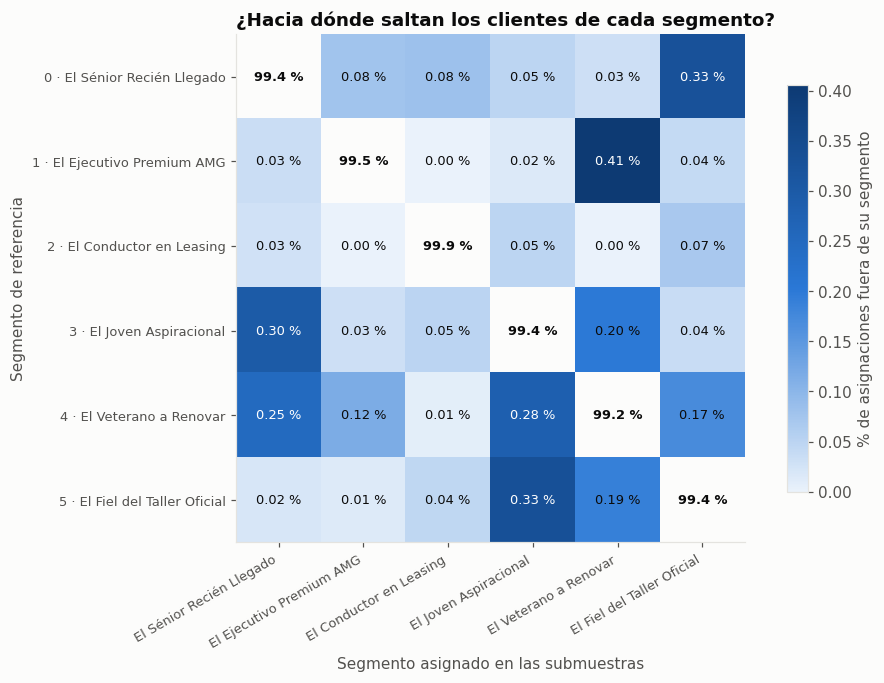

% de asignaciones
desde                          hacia                                            
1 · El Ejecutivo Premium AMG   4 · El Veterano a Renovar                    0.41
5 · El Fiel del Taller Oficial 3 · El Joven Aspiracional                    0.33
0 · El Sénior Recién Llegado   5 · El Fiel del Taller Oficial               0.33
3 · El Joven Aspiracional      0 · El Sénior Recién Llegado                 0.30
4 · El Veterano a Renovar      3 · El Joven Aspiracional                    0.28
                               0 · El Sénior Recién Llegado                 0.25

In [7]:
transiciones = np.zeros((K, K))
for r in range(N_SUBMUESTRAS):
    m = ASIGNACIONES[r] >= 0
    transiciones += pd.crosstab(REF[m], ASIGNACIONES[r][m]).reindex(index=range(K), columns=range(K), fill_value=0).to_numpy()
transiciones = transiciones / transiciones.sum(axis=1, keepdims=True) * 100
pd.DataFrame(transiciones, index=[NOMBRE[c] for c in range(K)], columns=[NOMBRE[c] for c in range(K)]).to_csv(
    ROOT / "reports" / "A3_transiciones.csv")

fuera = np.where(np.eye(K, dtype=bool), np.nan, transiciones)
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(fuera, cmap=ps.SEQ_BLUE, vmin=0, vmax=np.nanmax(fuera))
for i in range(K):
    for j in range(K):
        texto = f"{transiciones[i, j]:.1f} %" if i == j else f"{transiciones[i, j]:.2f} %"
        ax.text(j, i, texto, ha="center", va="center", fontsize=8.5,
                color=ps.INK if (i == j or transiciones[i, j] < np.nanmax(fuera) * 0.6) else "white",
                fontweight="bold" if i == j else "normal")
etiquetas = [NOMBRE[c] for c in range(K)]
ax.set_xticks(range(K), [e.split(" · ")[-1] for e in etiquetas], rotation=30, ha="right", fontsize=8.5)
ax.set_yticks(range(K), etiquetas, fontsize=8.5); ax.grid(False)
ax.set_xlabel("Segmento asignado en las submuestras"); ax.set_ylabel("Segmento de referencia")
fig.colorbar(im, ax=ax, shrink=0.8, label="% de asignaciones fuera de su segmento")
ax.set_title("¿Hacia dónde saltan los clientes de cada segmento?")
fig.savefig(FIG_DIR / "A3_transiciones.png", bbox_inches="tight"); plt.show()

saltos = (pd.DataFrame(fuera, index=etiquetas, columns=etiquetas).stack().rename("% de asignaciones").sort_values(ascending=False)
          .head(6).round(2).to_frame())
saltos.index.names = ["desde", "hacia"]
saltos

Los saltos se concentran entre **segmentos vecinos**, es decir, que comparten rasgos:

- Los clientes del **Veterano a Renovar** saltan hacia el Joven Aspiracional, el Sénior Recién Llegado y el Fiel del Taller Oficial: son
  clientes cuyo coche está cerca del límite de antigüedad que separa estos segmentos.
- Desde el **Ejecutivo Premium AMG** el salto principal va hacia el Veterano a Renovar: vehículos de gama alta y con años, a medio camino entre
  ambos perfiles.
- El resto de saltos relevantes (Sénior → Fiel, Fiel → Joven y Joven → Sénior) también unen perfiles parecidos en antigüedad como cliente
  o del vehículo.

No hay saltos entre segmentos muy distintos (por ejemplo, del Conductor en Leasing al Veterano), lo que confirma que la inestabilidad, cuando
existe, es un **ajuste de fronteras** y no un cambio en el significado de los segmentos.

### 4.3 Tamaño de los segmentos en cada submuestra

Si los segmentos fueran inestables, su tamaño variaría mucho de una ejecución a otra.

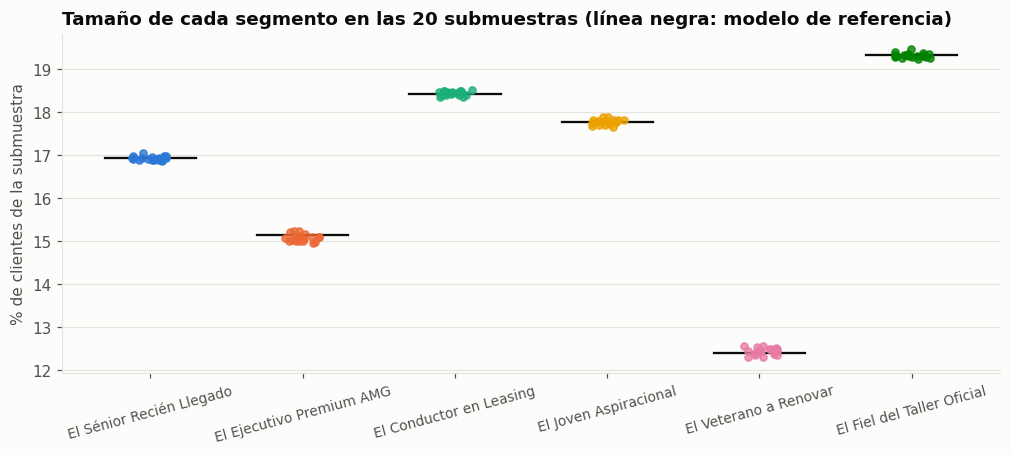

,variación máxima del tamaño (puntos porcentuales)
0 · El Sénior Recién Llegado,0.17
1 · El Ejecutivo Premium AMG,0.28
2 · El Conductor en Leasing,0.16
3 · El Joven Aspiracional,0.23
4 · El Veterano a Renovar,0.26
5 · El Fiel del Taller Oficial,0.23


In [8]:
tamanos = pd.DataFrame([[(ASIGNACIONES[r] == c).sum() / (ASIGNACIONES[r] >= 0).sum() * 100 for c in range(K)]
                        for r in range(N_SUBMUESTRAS)], columns=[NOMBRE[c] for c in range(K)])
referencia_pct = pd.Series(np.bincount(REF) / N_CLIENTES * 100, index=tamanos.columns)

fig, ax = plt.subplots(figsize=(11, 4))
for c, col in enumerate(tamanos.columns):
    ax.scatter(np.full(N_SUBMUESTRAS, c) + np.random.default_rng(c).uniform(-0.12, 0.12, N_SUBMUESTRAS), tamanos[col],
               s=22, color=ps.SERIES[c], alpha=0.8, zorder=3)
    ax.plot([c - 0.3, c + 0.3], [referencia_pct[col]] * 2, color=ps.INK, lw=1.5)
ax.set_xticks(range(K), [c.split(" · ")[-1] for c in tamanos.columns], rotation=15, fontsize=9)
ax.set_ylabel("% de clientes de la submuestra"); ax.set_axisbelow(True)
ax.set_title("Tamaño de cada segmento en las 20 submuestras (línea negra: modelo de referencia)")
fig.savefig(FIG_DIR / "A3_tamanos_submuestras.png"); plt.show()
variacion = (tamanos.max() - tamanos.min()).rename("variación máxima del tamaño (puntos porcentuales)")
variacion.to_csv(ROOT / "reports" / "A3_variacion_tamanos.csv")
variacion.round(2).to_frame()

El tamaño de cada segmento apenas cambia entre submuestras (variaciones de décimas de punto porcentual) y siempre está pegado al del modelo de
referencia. Los segmentos no "absorben" ni "pierden" clientes de forma relevante al cambiar los datos.

## 5. ¿Qué clientes saltan entre clústeres y por qué?

Si los clientes que saltan son los que ya estaban en la frontera entre dos segmentos, su **silueta** (sección 7 del cuaderno 03) debería ser baja:
una silueta cercana a 0 o negativa indica que el cliente está casi a la misma distancia de su clúster que del vecino. Lo comprobamos sobre una
muestra de 20.000 clientes, y comparamos también algunos rasgos de su perfil.

,clientes en la muestra,silueta media,% con silueta negativa
grupo,,,
Nunca cambian,19600,0.113,5.066
Saltan alguna vez,400,-0.001,47.750


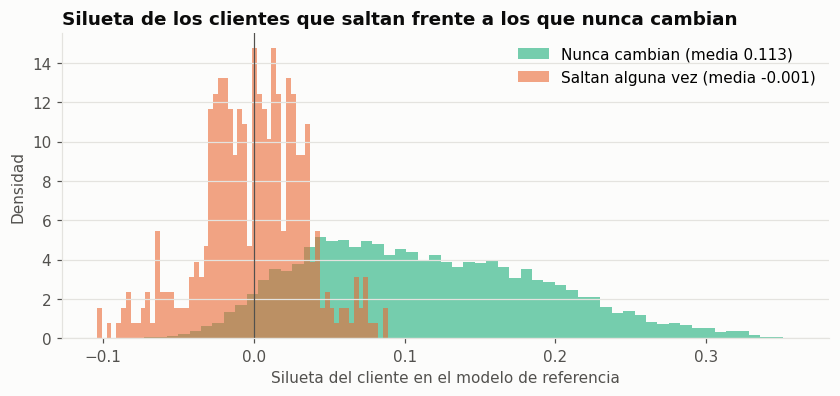

In [9]:
muestra = np.random.default_rng(0).choice(N_CLIENTES, 20_000, replace=False)
sil = silhouette_samples(X[muestra], REF[muestra])
grupo = np.where(estabilidad[muestra] == 100, "Nunca cambian", "Saltan alguna vez")
comparacion = (pd.DataFrame({"grupo": grupo, "silueta": sil})
               .groupby("grupo")["silueta"]
               .agg(**{"clientes en la muestra": "size", "silueta media": "mean",
                       "% con silueta negativa": lambda v: (v < 0).mean() * 100}))
comparacion.to_csv(ROOT / "reports" / "A3_silueta_saltan.csv")
display(comparacion.round(3))

fig, ax = plt.subplots(figsize=(9, 3.6))
for k, (g, color) in enumerate([("Nunca cambian", ps.SERIES[2]), ("Saltan alguna vez", ps.SERIES[1])]):
    datos = sil[grupo == g]
    ax.hist(datos, bins=60, density=True, alpha=0.6, color=color, label=f"{g} (media {datos.mean():.3f})")
ax.axvline(0, color=ps.INK_2, lw=0.8)
ax.set_xlabel("Silueta del cliente en el modelo de referencia"); ax.set_ylabel("Densidad"); ax.legend()
ax.set_title("Silueta de los clientes que saltan frente a los que nunca cambian")
fig.savefig(FIG_DIR / "A3_silueta_saltan.png"); plt.show()

In [10]:
perfil = pd.read_csv(DATA_DIR / "clientes_features.csv", low_memory=False, dtype={"client_id": str},
                     usecols=["client_id", "main_vehicle_age_years", "tenure_years", "warranty_visit_frequency",
                              "purchasing_power_per_household_eur"])
assert perfil["client_id"].is_unique
perfil = pd.DataFrame({"client_id": df_prepared.index, "estabilidad": estabilidad}).merge(
    perfil, on="client_id", how="left", validate="one_to_one")
assert len(perfil) == N_CLIENTES and perfil["main_vehicle_age_years"].notna().all()
perfil["grupo"] = np.where(perfil["estabilidad"] == 100, "Nunca cambian", "Saltan alguna vez")
perfil_saltan = (perfil.groupby("grupo")[["main_vehicle_age_years", "tenure_years", "warranty_visit_frequency",
                                          "purchasing_power_per_household_eur"]]
                 .median().rename(columns={"main_vehicle_age_years": "antigüedad vehículo (años)", "tenure_years": "años como cliente",
                                           "warranty_visit_frequency": "visitas taller/vehículo",
                                           "purchasing_power_per_household_eur": "poder adquisitivo (€)"}))
perfil_saltan.to_csv(ROOT / "reports" / "A3_perfil_saltan.csv")
perfil_saltan.round(2)

,antigüedad vehículo (años),años como cliente,visitas taller/vehículo,poder adquisitivo (€)
grupo,,,,
Nunca cambian,4.22,3.0,1.5,104111.89
Saltan alguna vez,6.31,3.0,1.0,99274.35


**Los clientes que saltan son clientes frontera.** Su silueta media es prácticamente 0, frente a la de los clientes que nunca cambian, y casi la
mitad la tiene negativa: ya en el modelo de referencia estaban tan cerca de otro segmento como del suyo. Además tienen, en mediana, un **vehículo
más antiguo**, lo que encaja con lo visto en la sección 4: la antigüedad del vehículo es la variable continua cuyo límite entre segmentos
(Veterano, Joven, Sénior, Fiel) es más difuso.

**Silueta y estabilidad no son lo mismo.** En el cuaderno 03, el segmento con peor silueta era el Ejecutivo Premium AMG (clúster 1), y aquí es
de los más estables. Es justo el matiz que plantea el reto: la silueta mide lo compacto y separado que está un grupo y la estabilidad mide si
se reproduce al cambiar los datos. El Ejecutivo Premium AMG es disperso (sus clientes se parecen poco entre sí), pero su frontera es nítida
porque se apoya en la gama del vehículo, una variable discreta.

In [11]:
pd.DataFrame({"client_id": df_prepared.index, "cluster": REF, "estabilidad_pct": estabilidad.round(1),
              "apariciones": apariciones}).to_csv(DATA_DIR / "jackknife_estabilidad_clientes.csv", index=False)
print("Guardado: data/jackknife_estabilidad_clientes.csv (estabilidad individual) y reports/A3_estabilidad_por_cluster.csv")

Guardado: data/jackknife_estabilidad_clientes.csv (estabilidad individual) y reports/A3_estabilidad_por_cluster.csv


## 6. Conclusiones y recomendación final

**¿Es estable la segmentación?** Sí. Al excluir aleatoriamente un 15 % de los clientes y volver a entrenar en 20 ocasiones:

- En cada submuestra, más del **99 % de los clientes** recibe el mismo segmento, tanto frente al modelo final como entre submuestras
  (ARI en torno a 0,99), y el **98 % de los clientes no cambia de segmento en ninguna** de las 20 ejecuciones.
- El **tamaño de los segmentos** apenas varía, unas décimas de punto.
- Solo una **pequeña minoría** de clientes cambia de segmento alguna vez, y casi siempre entre segmentos vecinos.

**Clústeres más y menos estables:**

| | Segmento | Por qué |
|---|---|---|
| Más estable | Conductor en Leasing | Se define por una variable binaria muy marcada (financiación activa): su frontera no se mueve |
| Menos estable | Veterano a Renovar (y, después, Joven Aspiracional) | Se distinguen por la antigüedad del vehículo, una variable continua cuyo límite entre segmentos es difuso |

**Clientes que saltan:** son clientes frontera, con silueta cercana a 0 y vehículos de antigüedad intermedia-alta, que oscilan entre
segmentos parecidos (Veterano ↔ Joven, Sénior, Fiel; Ejecutivo → Veterano). No cambian de perfil, sino de lado de una frontera.

**Recomendación final:**

1. **Usar la segmentación de K-Means con k = 6 para las decisiones de marketing.** Es robusta: los segmentos y su tamaño se mantienen al cambiar
   los clientes de entrenamiento, así que las campañas diseñadas sobre ellos se dirigirán a grupos reales y consistentes.
2. **Tratar con cautela a los clientes inestables** (estabilidad inferior al 80 %, guardada por cliente en `jackknife_estabilidad_clientes.csv`).
   No conviene excluirlos, pero sí evitar acciones muy específicas de segmento y, en su lugar, combinar las campañas de los dos segmentos
   entre los que oscilan (por ejemplo, un Veterano a Renovar que salta al Joven Aspiracional puede recibir tanto la oferta de renovación como la
   de primera financiación).
3. **Vigilar el segmento Veterano a Renovar** al reentrenar el modelo con datos nuevos: es el más sensible. Si en el futuro se quisiera reforzar
   su estabilidad, una opción sería añadir una variable más nítida para ese perfil (por ejemplo, un indicador de vehículo fuera de garantía),
   validándolo de nuevo con este mismo procedimiento de Jackknife.
4. **Repetir este análisis** cada vez que se reentrene el modelo, como control de calidad antes de lanzar campañas.